# Разбор упражнений к лекции 7

Условия — раздел 9 конспекта [`lecture07.md`](lecture07.md); краткие ответы без кода — [`exercises07.md`](exercises07.md). Все задачи домашние. **Сначала попробуйте сами**, потом сверяйтесь. Каждый разбор: условие → решение по пунктам → проверка кодом и картинка там, где она помогает. Нужен CasADi: `uv run --group casadi jupyter lab`; в Colab первая ячейка ставит его сама.

In [1]:
%matplotlib inline

import importlib.util, subprocess, sys
if importlib.util.find_spec("casadi") is None:          # Colab: поставить CasADi один раз
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "casadi"], check=True)

import casadi as ca
import numpy as np
import matplotlib.pyplot as plt
from l7helpers import *  # разности, мини-АД, цепь (собираются из build_demo07.py)

## 7.0. Разминка — счёт руками

**Условие.** Три пункта по минуте. *Суть: две ошибки и счёт проходов — на бумаге.*

- (а) $f(x)=e^x$ в $x=0$, прямая разность. Оцените ошибку при $h=10^{-4}$ и при $h=10^{-12}$ по формулам §2.1 — и скажите, какая из двух ошибок главная в каждом случае.
- (б) Якобиан $3\times1000$: сколько проходов нужно прямому режиму, сколько обратному? А для якобиана $1000\times3$?
- (в) Сколько проходов «назад по прямому» нужно на полный гессиан $n\times n$ без учёта разреженности?

**Решение.**

**(а)** $f=e^x$, $f''=1$, $\lvert f\rvert=1$ в нуле. Усечение $\tfrac h2$, округление $\tfrac{2\varepsilon}{h}$. При $h=10^{-4}$: усечение $5\cdot10^{-5}$, округление $4\cdot10^{-12}$ — главная ошибка усечения. При $h=10^{-12}$: усечение $5\cdot10^{-13}$, округление $4\cdot10^{-4}$ — главная ошибка округления, и она в десять раз больше, чем при $h=10^{-4}$.

**(б)** Якобиан $3\times1000$: прямому режиму нужен проход на каждый из $1000$ столбцов, обратному — на каждую из $3$ строк: $1000$ против $3$. Якобиан $1000\times3$ — наоборот: вперёд $3$, назад $1000$.

**(в)** Гессиан $n\times n$ — $n$ проходов «назад по прямому» (по одному на столбец $\nabla^2f\,e_i$), каждый ценой нескольких $f$; CasADi сокращает это за счёт разреженности.

In [2]:
fexp = lambda x: np.exp(x[0])
for h in (1e-4, 1e-12):
    print(f"7.0(а) h = {h:.0e}: ошибка прямой разности {abs(fd_forward(fexp, np.array([0.0]), 0, h) - 1):.1e}  (усечение h/2 = {h / 2:.0e}, округление 2 eps / h = {2 * EPS / h:.0e})")

7.0(а) h = 1e-04: ошибка прямой разности 5.0e-05  (усечение h/2 = 5e-05, округление 2 eps / h = 4e-12)
7.0(а) h = 1e-12: ошибка прямой разности 8.9e-05  (усечение h/2 = 5e-13, округление 2 eps / h = 4e-04)


## 7.1. U-кривая своими руками

**Условие.** (с кодом). *Суть: наклоны веток — это показатели степени $h$ и $1/h$.*

- (а) Постройте U-кривые прямой и центральной разности для $\sin x$ в $x=1$, $h$ от $10^{-15}$ до $10^{-1}$. Найдите лучшие $h$ и ошибки; оцените наклоны веток в логарифмических осях.
- (б) Повторите для квадратичной $3x^2+x$ в $x=1$ с центральной разностью. Почему у U-кривой осталась одна ветка?

**Решение.**

**(а)** $\sin$ в $x=1$: прямая разность — лучший $h\approx2.5\cdot10^{-9}$, ошибка $2\cdot10^{-9}$; центральная — $h\approx3\cdot10^{-6}$, ошибка $6\cdot10^{-13}$. Наклоны: справа $1$ и $2$, слева $-1$ — степени $h$ в ошибке усечения и $1/h$ в ошибке округления.

**(б)** У квадратичной $f'''\equiv0$, поэтому ошибка усечения центральной разности равна нулю при любом $h$: остаётся одна ветка — округление, растущее при $h\to0$; при $h=0.1$ ошибка уже на уровне $10^{-15}$.

7.1(а) прямая      : лучший h 2.5e-09, ошибка 2.2e-09, наклоны 1.00 / -1.00
7.1(а) центральная : лучший h 3.2e-06, ошибка 6.0e-13, наклоны 2.00 / -1.04
7.1(б) квадратичная, центральная: при h = 0.1 ошибка 1.8e-15, при h = 1e-12 — 1.8e-04


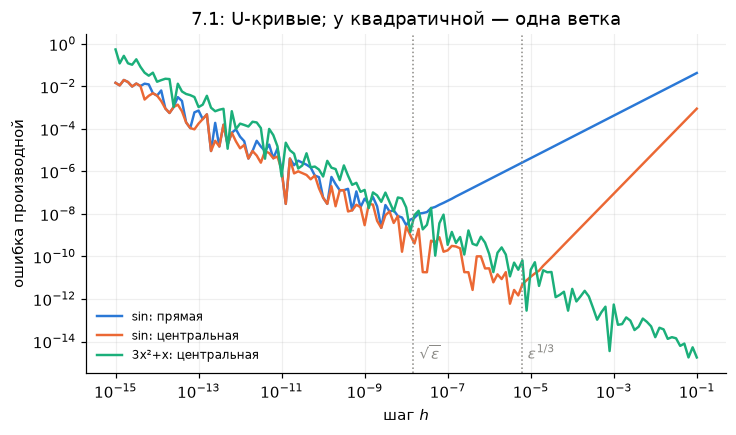

In [3]:
fsin = lambda x: np.sin(x[0])
ef, ec = ucurve(fsin, np.array([1.0]), 0, np.cos(1.0))
slope = lambda e, lo, hi: np.polyfit(np.log10(HS[(HS >= lo) & (HS <= hi)]), np.log10(e[(HS >= lo) & (HS <= hi)]), 1)[0]
for name, e, lo in (("прямая", ef, 1e-6), ("центральная", ec, 1e-4)):
    j = np.argmin(e); print(f"7.1(а) {name:12s}: лучший h {HS[j]:.1e}, ошибка {e[j]:.1e}, наклоны {slope(e, lo, 1e-1):.2f} / {slope(e, 1e-15, 1e-10):.2f}")
fq = lambda x: 3 * x[0] ** 2 + x[0]
eq = np.array([abs(fd_central(fq, np.array([1.0]), 0, h) - 7) for h in HS])
print(f"7.1(б) квадратичная, центральная: при h = 0.1 ошибка {eq[-1]:.1e}, при h = 1e-12 — {eq[np.argmin(abs(HS - 1e-12))]:.1e}")
fig, ax = plt.subplots(figsize=(7.5, 4))
ucurve_plot(ax, [ef, ec, eq], ["sin: прямая", "sin: центральная", "3x²+x: центральная"], [BLUE, ORANGE, AQUA])
ax.set(title="7.1: U-кривые; у квадратичной — одна ветка"); plt.show()

## 7.2. Прямой режим руками

**Условие.** *Суть: $\dot v$ течёт вместе с $v$.*

$f(x_1,x_2)=e^{x_1}x_2+x_1^2$ в точке $(0,1)$. Запишите программу из четырёх операций ($v_1=e^{x_1}$, $v_2=v_1x_2$, $v_3=x_1^2$, $f=v_2+v_3$) и выполните прямой режим по направлению $d=(1,1)$: все $\dot v_i$ и $\dot f$. Проверьте по формуле $\nabla f^\top d$.

**Решение.**

В $(0,1)$ по $d=(1,1)$: $v_1=e^{0}=1$, $\dot v_1=e^{x_1}\dot x_1=1$; $v_2=v_1x_2=1$, $\dot v_2=\dot v_1x_2+v_1\dot x_2=1+1=2$; $v_3=x_1^2=0$, $\dot v_3=2x_1\dot x_1=0$; $f=v_2+v_3=1$, $\dot f=\dot v_2+\dot v_3=2$. Проверка: $\nabla f=(e^{x_1}x_2+2x_1,\ e^{x_1})=(1,1)$, $\nabla f^\top d=2$.

In [4]:
PROGRAM2 = [("v1", "exp", ("x1",)), ("v2", "mul", ("v1", "x2")), ("v3", "sq", ("x1",)), ("f", "add", ("v2", "v3"))]
val, dot = forward_mode(PROGRAM2, {"x1": 0.0, "x2": 1.0}, {"x1": 1.0, "x2": 1.0})
print("7.2 значения:", {k: round(v, 4) for k, v in val.items()}, " прямой режим:", {k: round(v, 4) for k, v in dot.items()})
assert dot["f"] == 2.0

7.2 значения: {'x1': 0.0, 'x2': 1.0, 'v1': np.float64(1.0), 'v2': np.float64(1.0), 'v3': 0.0, 'f': np.float64(1.0)}  прямой режим: {'x1': 1.0, 'x2': 1.0, 'v1': np.float64(1.0), 'v2': np.float64(2.0), 'v3': 0.0, 'f': np.float64(2.0)}


## 7.3. Обратный режим руками

**Условие.** (с кодом). *Суть: доли чувствительности складываются там, где у величины два потребителя.*

- (а) Та же функция и точка, что в 7.2: выполните обратный проход, получите $\bar x_1$, $\bar x_2$ и сверьте с $\nabla f$.
- (б) Мини-задание лекции: $f=x_1x_2+\sin(x_1x_2)$ в $(1,\pi)$ — $\bar v_1$ и $\nabla f$. Проверьте обе функции через `ca.gradient`.

**Решение.**

**(а)** $\bar f=1$; $f=v_2+v_3$: $\bar v_2=1$, $\bar v_3=1$; $v_3=x_1^2$: $\bar x_1\mathrel{+}=\bar v_3\cdot2x_1=0$; $v_2=v_1x_2$: $\bar v_1=\bar v_2x_2=1$, $\bar x_2=\bar v_2v_1=1$; $v_1=e^{x_1}$: $\bar x_1\mathrel{+}=\bar v_1e^{x_1}=1$. Итого $\nabla f=(1,1)$ — совпало с 7.2, и $\bar x_1$ собран из двух долей ($0$ через $x_1^2$ и $1$ через $e^{x_1}$).

**(б)** В $(1,\pi)$: $v_1=\pi$, $\bar v_2=1$, $\bar v_1=1+\cos\pi=0$, $\nabla f=(\bar v_1x_2,\ \bar v_1x_1)=(0,0)$ — стационарная точка: на кривой $x_1x_2=\pi$ производная $f$ по $v_1$ обращается в ноль.

In [5]:
val, bar = reverse_mode(PROGRAM2, {"x1": 0.0, "x2": 1.0})
print("7.3(а) обратный режим:", {k: round(v, 4) for k, v in bar.items()})
x2 = ca.SX.sym("x", 2)
for name, prog, expr, pt in (("7.3(а)", PROGRAM2, ca.exp(x2[0]) * x2[1] + x2[0] ** 2, [0.0, 1.0]),
                             ("7.3(б)", PROGRAM, x2[0] * x2[1] + ca.sin(x2[0] * x2[1]), [1.0, np.pi])):
    _, bar = reverse_mode(prog, {"x1": pt[0], "x2": pt[1]})
    g_ca = np.array(ca.Function("g", [x2], [ca.gradient(expr, x2)])(pt)).ravel()
    print(f"{name}: руками ({bar['x1']:.4f}, {bar['x2']:.4f}), CasADi {g_ca.round(4)}")
    assert np.allclose([bar["x1"], bar["x2"]], g_ca, atol=1e-12)

7.3(а) обратный режим: {'x1': np.float64(1.0), 'x2': np.float64(1.0), 'v1': 1.0, 'v2': 1.0, 'v3': 1.0, 'f': 1.0}
7.3(а): руками (1.0000, 1.0000), CasADi [1. 1.]
7.3(б): руками (0.0000, 0.0000), CasADi [0. 0.]


## 7.4. Мнимый трюк

**Условие.** (для желающих). *Суть: вычитания нет — нет и ошибки округления.*

Для вещественно-аналитической $f$ верно $f(x+ih)=f(x)+ihf'(x)-\tfrac{h^2}{2}f''(x)-\dots$, откуда $f'(x)\approx\operatorname{Im}f(x+ih)/h$ с ошибкой усечения $\sim h^2$ и **без вычитания**. Проверьте на Розенброке в $(-1.2,1)$ при $h=10^{-20}$ (ожидается ошибка $\sim10^{-14}$ при производной $-215.6$). Почему трюк не работает для $\lvert x\rvert$ и для функций с `if x > 0`?

**Решение.**

Для аналитической $f$: $f(x+ih)=f(x)+ihf'(x)-\tfrac{h^2}2f''(x)-i\tfrac{h^3}6f'''(x)+\dots$, мнимая часть $hf'(x)-\tfrac{h^3}{6}f'''(x)+\dots$, значит $\operatorname{Im}f(x+ih)/h=f'(x)+O(h^2)$. Вычитать нечего: мнимая часть считается с относительной точностью $\varepsilon$, и $h$ можно брать $10^{-20}$ — ошибка усечения $10^{-40}$, округления нет; на Розенброке ошибка $3\cdot10^{-14}$ при $\lvert f'\rvert=215.6$, то есть $10^{-16}$ относительно. Не работает там, где $f$ не аналитична: $\lvert x\rvert$ (модуль комплексного числа — вещественное, мнимая часть пропадает), `if x > 0` (сравнение комплексных чисел не определено), `max`, `round`.

In [6]:
h = 1e-20
z = X0_ROSEN.astype(complex); z[0] += 1j * h
print(f"7.4 мнимый трюк: ошибка {abs(np.imag(rosen(z)) / h - rosen_grad(X0_ROSEN)[0]):.1e}; лучшая прямая разность: {ucurve(rosen, X0_ROSEN, 0, rosen_grad(X0_ROSEN)[0])[0].min():.1e}")

7.4 мнимый трюк: ошибка 2.8e-14; лучшая прямая разность: 1.4e-06


## 7.5. Разреженность и гессиан на вектор

**Условие.** (с кодом). *Суть: гессиан цепи — ленты, и CasADi это знает.*

Для упругой цепи с $N=10,\ 40,\ 160$ грузиками постройте через CasADi энергию, гессиан и произведение $\nabla^2E\,d$ как `jtimes(gradient(E, v), v, d)`. Для каждого $N$ выпишите `n_instructions()` энергии, гессиана и произведения и долю ненулевых элементов гессиана. Почему доля падает с $N$, а цена произведения на вектор остаётся $\approx3.3$ цены $E$?

**Решение.**

Доля ненулевых падает как $1/N$: у каждой строки гессиана не больше шести ненулевых соседей при $2N$ столбцах ($28\,\%$ при $N=10$, $7\,\%$ при $40$, $2\,\%$ при $160$). Произведение $\nabla^2E\,d$ — один проход «назад по прямому» ценой $\approx3.3$ операций $E$ независимо от $N$: это прямой режим, применённый к программе обратного прохода, а она сама стоит $1.6$. Полный гессиан стоит $5$–$6$ цен $E$ только благодаря разреженности: CasADi собирает несколько столбцов за один проход.

In [7]:
print(f"{'N':>5s} {'E':>6s} {'H':>6s} {'H d':>6s}   ненулевых")
for N in (10, 40, 160):
    nf, ng, nh, nhd, nnz = chain_costs(N)
    print(f"{N:5d} {nf:6d} {nh:6d} {nhd:6d}   {nnz} из {(2 * N) ** 2} = {100 * nnz / (2 * N) ** 2:.1f} %   (гессиан x{nh / nf:.1f}, H d x{nhd / nf:.1f})")

    N      E      H    H d   ненулевых
   10    147    743    469   112 из 400 = 28.0 %   (гессиан x5.1, H d x3.2)
   40    537   2968   1759   472 из 6400 = 7.4 %   (гессиан x5.5, H d x3.3)
  160   2097  11868   6919   1912 из 102400 = 1.9 %   (гессиан x5.7, H d x3.3)
